# Análisis Exploratorio: Tipo de Cambio USD/MXN, Inflación (INPC) y Variables Macroeconómicas

Este notebook permite explorar y contrastar la relación entre el **Tipo de Cambio FIX (USD/MXN)**, la **Inflación Anual (INPC)**, las finanzas públicas (ingresos y gastos reales) y los sectores del IGAE, utilizando la Capa Gold generada en `data/processed/proyecto_integrado_mensual.parquet`.

El análisis se realiza a través de **rendimientos y variaciones interanuales (12 meses)** para garantizar comparabilidad entre variables.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajuste al directorio raíz si se ejecuta dentro de notebooks/
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "pipeline.py").exists():
    os.chdir("..")

DATA_PATH = Path("data/processed/proyecto_integrado_mensual.parquet")
print("Ruta del dataset:", DATA_PATH)

df = pd.read_parquet(DATA_PATH)
df["PERIODO"] = pd.to_datetime(df["PERIODO"])
df = df.sort_values("PERIODO").reset_index(drop=True)

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head(5))

Ruta del dataset: data\processed\proyecto_integrado_mensual.parquet
Dimensiones: 187 filas x 10 columnas


,PERIODO,INGRESOS_REALES,GASTOS_REALES,Total,INPC,Actividades primarias,Actividades secundarias,Actividades terciarias,TC_CIERRE,SP500_CIERRE
0,2011-01-01,4.380374e+08,4.269849e+08,81.059540,75.295991,79.408239,86.769780,77.907893,12.1519,1286.119995
1,2011-02-01,3.309457e+08,3.598848e+08,80.115615,75.578460,70.907183,85.142158,77.773358,12.1062,1327.219971
2,2011-03-01,3.418151e+08,3.751086e+08,87.173674,75.723451,73.788636,92.861741,84.688332,11.9084,1325.829956
3,2011-04-01,3.553345e+08,3.637086e+08,82.957170,75.717441,74.688351,89.345867,79.788808,11.5278,1363.609985
4,2011-05-01,3.407529e+08,3.688092e+08,86.038632,75.159264,84.999197,90.934982,83.315218,11.5780,1345.199951


In [2]:
# Verificación de esquema, columnas y ausencia de nulos
df.info()
print("\nEstadísticas descriptivas en niveles:")
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype        
---  ------                   --------------  -----        
 0   PERIODO                  187 non-null    datetime64[s]
 1   INGRESOS_REALES          187 non-null    float64      
 2   GASTOS_REALES            187 non-null    float64      
 3   Total                    187 non-null    float64      
 4   INPC                     187 non-null    float64      
 5   Actividades primarias    187 non-null    float64      
 6   Actividades secundarias  187 non-null    float64      
 7   Actividades terciarias   187 non-null    float64      
 8   TC_CIERRE                187 non-null    float64      
 9   SP500_CIERRE             187 non-null    float64      
dtypes: datetime64[s](1), float64(9)
memory usage: 14.7 KB

Estadísticas descriptivas en niveles:


,count,mean,min,25%,50%,75%,max,std
PERIODO,187,2018-10-01 02:41:42,2011-01-01 00:00:00,2014-11-16 00:00:00,2018-10-01 00:00:00,2022-08-16 12:00:00,2026-07-01 00:00:00,NaN
INGRESOS_REALES,187.0,449203176.048268,301937488.94385,388194667.61287,433478112.936665,491749739.657529,965802620.148427,90004582.81026
GASTOS_REALES,187.0,532618368.15454,348747173.12156,439932753.156568,489316713.692185,599967846.802232,998390059.227312,132917440.430379
Total,187.0,96.791165,76.331455,91.915073,97.383327,101.358937,109.210136,6.634553
INPC,187.0,104.797432,75.155508,86.865572,101.44,124.187,145.831,21.540708
Actividades primarias,187.0,97.347046,60.127364,83.956339,95.609243,110.192043,148.33748,18.359436
Actividades secundarias,187.0,97.798869,69.748162,95.459659,98.083349,101.276702,107.393644,5.058086
Actividades terciarias,187.0,96.187781,77.773358,90.058032,96.653942,102.123695,112.444236,8.026706
TC_CIERRE,187.0,17.421223,11.5278,14.52305,18.3075,19.71425,23.9283,3.007752
SP500_CIERRE,187.0,3232.482937,1131.420044,1972.235046,2752.060059,4246.079834,7580.060059,1645.945134


## Justificación Metodológica: Uso de Rendimientos e Inflación Anual (12 Meses)

Comparar variables macroeconómicas y financieras en niveles brutos (pesos por dólar, puntos de índice de precios o millones de pesos) genera dos problemas:
1. **Diferencia de escalas:** Las unidades de medida son heterogéneas e incomparables de forma directa.
2. **Tendencias temporales y correlación espuria:** Series que crecen por tendencia histórica pueden mostrar correlaciones altas sin que exista una relación económica subyacente.

**Transformación a variaciones interanuales (12 meses):**
$$\text{Rendimiento}_{t} = \left( \frac{X_t - X_{t-12}}{X_{t-12}} \right) \times 100$$

* En el **Tipo de Cambio (`RET_TC_CIERRE`)**, representa la tasa porcentual anual de depreciación (+) o apreciación (-) del peso.
* En el **INPC (`RET_INPC`)**, representa exactamente la **Inflación General Anual de México (%)**.
* En los **Ingresos y Gastos Reales**, representa la tasa de crecimiento real anual (%).
* En el **IGAE**, representa el crecimiento económico anual (%) de cada sector.

In [3]:
cols_analisis = [
    "TC_CIERRE", "INPC", "INGRESOS_REALES", "GASTOS_REALES",
    "Total", "Actividades primarias", "Actividades secundarias", "Actividades terciarias"
]

# Cálculo de variaciones interanuales a 12 meses
df_ret = df[["PERIODO"]].copy()
for col in cols_analisis:
    df_ret[f"RET_{col}"] = df[col].pct_change(12) * 100.0

# Se descartan los primeros 12 meses por cálculo de rezago
df_ret = df_ret.dropna().reset_index(drop=True)

print(f"Dimensiones en rendimientos: {df_ret.shape[0]} periodos observables (12 meses descontados)")
display(df_ret.head(5))
display(df_ret.describe().T[["count", "mean", "std", "min", "50%", "max"]])

Dimensiones en rendimientos: 175 periodos observables (12 meses descontados)


,PERIODO,RET_TC_CIERRE,RET_INPC,RET_INGRESOS_REALES,RET_GASTOS_REALES,RET_Total,RET_Actividades primarias,RET_Actividades secundarias,RET_Actividades terciarias
0,2012-01-01,7.042520,4.046773,6.890452,3.989315,5.302365,1.346244,5.095596,5.657826
1,2012-02-01,5.640911,3.868633,2.622574,19.415693,6.467091,6.706632,7.717587,5.677291
2,2012-03-01,7.565248,3.729278,0.630514,11.787457,3.379962,2.985400,4.437537,2.740391
3,2012-04-01,12.720554,3.412079,10.196847,6.883164,4.476649,7.777594,4.416622,4.342684
4,2012-05-01,23.550700,3.851228,-11.391069,-0.744380,4.750594,5.216749,5.825139,4.057890


,count,mean,std,min,50%,max
PERIODO,175,2019-04-01 18:14:24,NaN,2012-01-01 00:00:00,2019-04-01 00:00:00,2026-07-01 00:00:00
RET_TC_CIERRE,175.0,3.066951,10.889454,-17.781163,1.960576,28.345939
RET_INPC,175.0,4.484214,1.470485,2.130813,4.217584,8.69975
RET_INGRESOS_REALES,175.0,3.547354,16.50818,-52.992824,2.829016,103.978511
RET_GASTOS_REALES,175.0,4.250263,13.731196,-36.429049,3.852213,58.892405
RET_Total,175.0,1.553802,4.765007,-24.111348,1.836666,27.71047
RET_Actividades primarias,175.0,2.275302,5.534505,-14.34879,1.904334,24.932061
RET_Actividades secundarias,175.0,0.858684,5.965528,-30.031449,0.913141,37.127202
RET_Actividades terciarias,175.0,1.945673,4.556436,-22.267712,2.330276,24.951881


## Serie de Tiempo: Tipo de Cambio vs. Inflación Anual (INPC)
Permite observar visualmente si las fluctuaciones o depreciaciones bruscas del tipo de cambio coinciden o anteceden a presiones en la inflación general nacional (**efecto traspaso o pass-through**).

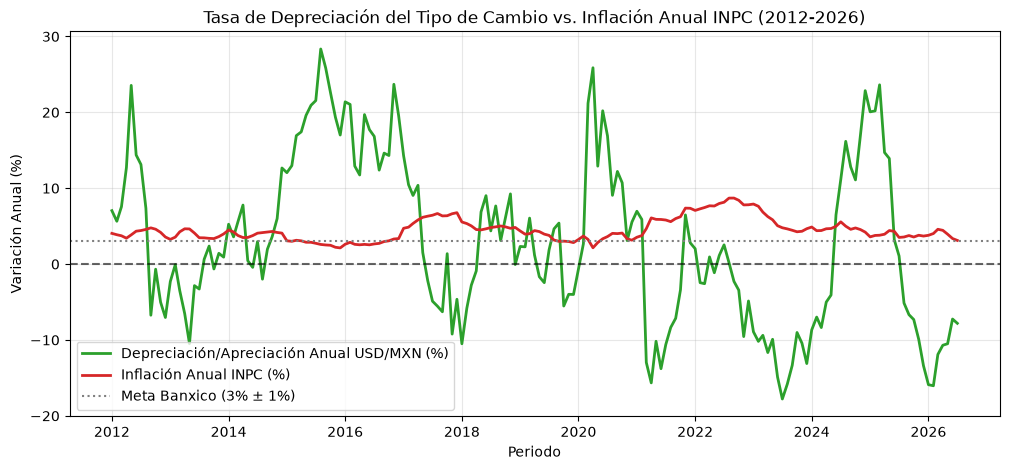

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_TC_CIERRE"], label="Depreciación/Apreciación Anual USD/MXN (%)", color="tab:green", linewidth=2)
plt.plot(df_ret["PERIODO"], df_ret["RET_INPC"], label="Inflación Anual INPC (%)", color="tab:red", linewidth=2)
plt.axhline(0, color="black", linestyle="--", alpha=0.6)
plt.axhline(3, color="gray", linestyle=":", label="Meta Banxico (3% ± 1%)")

plt.title("Tasa de Depreciación del Tipo de Cambio vs. Inflación Anual INPC (2012-2026)")
plt.xlabel("Periodo")
plt.ylabel("Variación Anual (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Serie de Tiempo: Tipo de Cambio vs. Finanzas Públicas Reales
Muestra la tasa de crecimiento interanual del tipo de cambio frente al crecimiento real de los ingresos y gastos del Gobierno Federal.

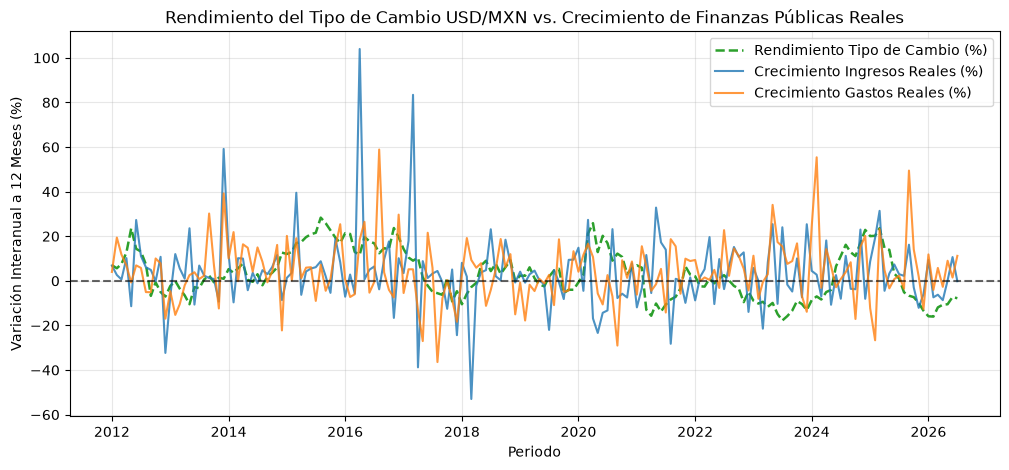

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_TC_CIERRE"], label="Rendimiento Tipo de Cambio (%)", color="tab:green", linestyle="--", linewidth=1.8)
plt.plot(df_ret["PERIODO"], df_ret["RET_INGRESOS_REALES"], label="Crecimiento Ingresos Reales (%)", color="tab:blue", alpha=0.8)
plt.plot(df_ret["PERIODO"], df_ret["RET_GASTOS_REALES"], label="Crecimiento Gastos Reales (%)", color="tab:orange", alpha=0.8)
plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.title("Rendimiento del Tipo de Cambio USD/MXN vs. Crecimiento de Finanzas Públicas Reales")
plt.xlabel("Periodo")
plt.ylabel("Variación Interanual a 12 Meses (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Serie de Tiempo: Tipo de Cambio vs. Crecimiento de Sectores IGAE
Compara la variación cambiaria con el ritmo de crecimiento anual de la economía total, industrial (secundarias) y comercial/servicios (terciarias).

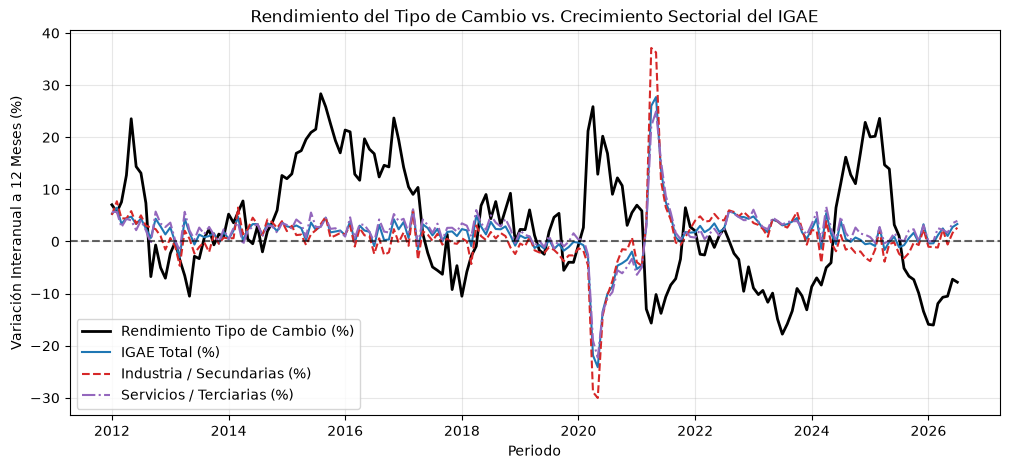

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_TC_CIERRE"], label="Rendimiento Tipo de Cambio (%)", color="black", linewidth=2)
plt.plot(df_ret["PERIODO"], df_ret["RET_Total"], label="IGAE Total (%)", color="tab:blue")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades secundarias"], label="Industria / Secundarias (%)", color="tab:red", linestyle="--")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades terciarias"], label="Servicios / Terciarias (%)", color="tab:purple", linestyle="-.")
plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.title("Rendimiento del Tipo de Cambio vs. Crecimiento Sectorial del IGAE")
plt.xlabel("Periodo")
plt.ylabel("Variación Interanual a 12 Meses (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Diagramas de Dispersión (Scatter Plots)
Exploración de la dispersión del rendimiento del Tipo de Cambio frente a la Inflación, el IGAE Total, la Industria y los Ingresos Reales.

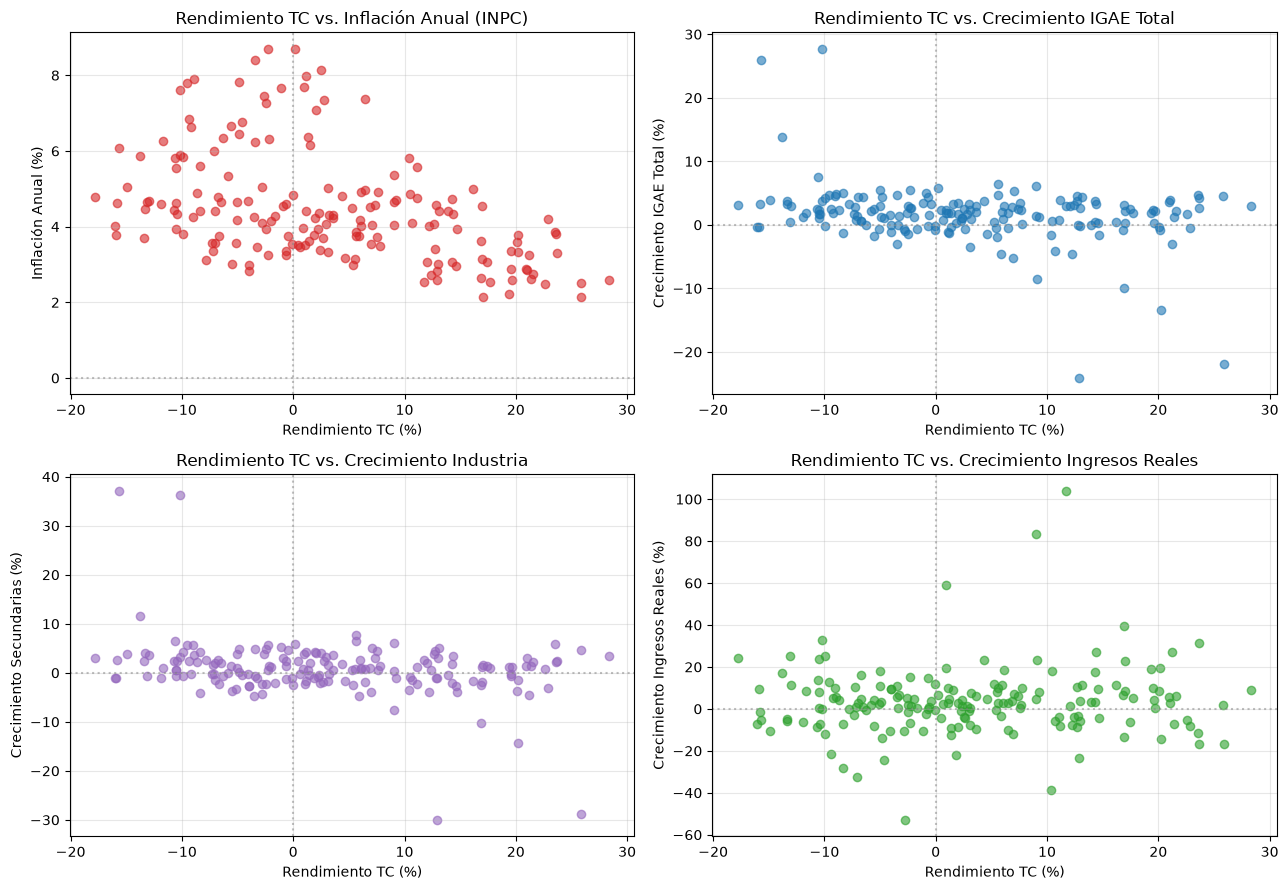

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# TC vs Inflación (INPC)
axes[0, 0].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_INPC"], alpha=0.6, color="tab:red")
axes[0, 0].set_title("Rendimiento TC vs. Inflación Anual (INPC)")
axes[0, 0].set_xlabel("Rendimiento TC (%)")
axes[0, 0].set_ylabel("Inflación Anual (%)")
axes[0, 0].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 0].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 0].grid(True, alpha=0.3)

# TC vs IGAE Total
axes[0, 1].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_Total"], alpha=0.6, color="tab:blue")
axes[0, 1].set_title("Rendimiento TC vs. Crecimiento IGAE Total")
axes[0, 1].set_xlabel("Rendimiento TC (%)")
axes[0, 1].set_ylabel("Crecimiento IGAE Total (%)")
axes[0, 1].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 1].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[0, 1].grid(True, alpha=0.3)

# TC vs IGAE Secundarias (Industria)
axes[1, 0].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_Actividades secundarias"], alpha=0.6, color="tab:purple")
axes[1, 0].set_title("Rendimiento TC vs. Crecimiento Industria")
axes[1, 0].set_xlabel("Rendimiento TC (%)")
axes[1, 0].set_ylabel("Crecimiento Secundarias (%)")
axes[1, 0].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 0].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 0].grid(True, alpha=0.3)

# TC vs Ingresos Reales
axes[1, 1].scatter(df_ret["RET_TC_CIERRE"], df_ret["RET_INGRESOS_REALES"], alpha=0.6, color="tab:green")
axes[1, 1].set_title("Rendimiento TC vs. Crecimiento Ingresos Reales")
axes[1, 1].set_xlabel("Rendimiento TC (%)")
axes[1, 1].set_ylabel("Crecimiento Ingresos Reales (%)")
axes[1, 1].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 1].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Matriz de Correlación Lineal de Pearson (Rendimientos)
Medición paramétrica única de la asociación lineal entre las variaciones interanuales.

Correlación de Pearson frente al Rendimiento del Tipo de Cambio:


,RET_TC_CIERRE
RET_TC_CIERRE,1.0000
RET_INPC,-0.4572
RET_INGRESOS_REALES,0.0708
RET_GASTOS_REALES,-0.0035
RET_Total,-0.2900
RET_Actividades primarias,0.0413
RET_Actividades secundarias,-0.2829
RET_Actividades terciarias,-0.2878


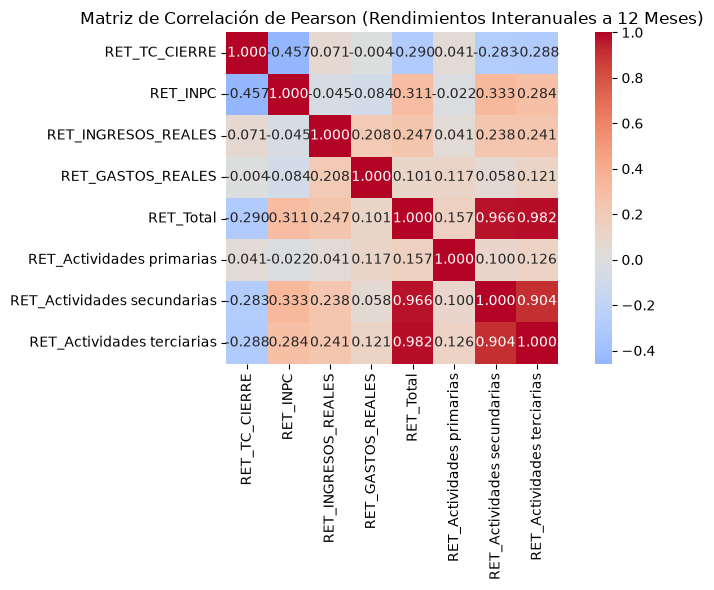

In [8]:
cols_ret = [f"RET_{c}" for c in cols_analisis]
corr_ret = df_ret[cols_ret].corr(method="pearson")

print("Correlación de Pearson frente al Rendimiento del Tipo de Cambio:")
display(corr_ret[["RET_TC_CIERRE"]].round(4))

plt.figure(figsize=(9, 6))
sns.heatmap(corr_ret, annot=True, cmap="coolwarm", center=0, fmt=".3f", square=True)
plt.title("Matriz de Correlación de Pearson (Rendimientos Interanuales a 12 Meses)")
plt.tight_layout()
plt.show()